In [1]:

# Jeevan Link — SOS Urgency EDA
# Step 1: Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load the cleaned SOS urgency dataset

from pathlib import Path
import pandas as pd

# Exact path to your existing cleaned dataset
file_path = Path(
    r"C:\Users\ishit\jeevan_link_ml\Data\Processed_data\sos_urgency_dataset\sos_urgency_dataset_final_cleaned.csv"
)

# Check whether the dataset exists
if not file_path.exists():
    raise FileNotFoundError(f"Dataset not found: {file_path}")

# Load the CSV file
df = pd.read_csv(file_path)

# Display basic dataset information
print("SOS urgency dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five rows
display(df.head())


SOS urgency dataset loaded successfully!
Number of rows: 4154
Number of columns: 19


,people_affected,people_trapped,injuries_reported,medical_emergency,rescue_required,food_required,water_required,shelter_required,urgency_label,water_level_Rapidly_Rising,water_level_Rising,water_level_Stable,building_condition_Collapsing,building_condition_Damaged,building_condition_Intact,building_condition_Unknown,location_risk_High,location_risk_Low,location_risk_Medium
0,4.0,1,0,0,1,0,1,0,Critical,1,0,0,0,0,1,0,1,0,0
1,1.0,1,1,1,1,0,0,0,Critical,0,1,0,0,1,0,0,1,0,0
2,1.0,1,0,0,1,0,0,0,Critical,1,0,0,0,0,0,1,1,0,0
3,6.0,1,1,0,1,0,0,1,Critical,0,1,0,0,1,0,0,1,0,0
4,5.0,0,0,0,1,0,1,1,High,0,1,0,0,0,1,0,1,0,0


In [3]:

# Find CSV files inside your Processed_data folder

from pathlib import Path

processed_folder = Path(
    r"C:\Users\ishit\jeevan_link_ml\Data\Processed_data"
)

for file in processed_folder.rglob("*.csv"):
    print(file)


C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\disaster_response_test_preprocessing_report.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\disaster_response_test_processed.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\disaster_response_training_preprocessing_report.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\disaster_response_training_processed.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\disaster_response_validation_preprocessing_report.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\disaster_response_validation_processed.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\Disaster Response Messages\sos_urgency_dataset_builder.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\ifi_processed_Data\DFSI_processed.csv
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\ifi_processed_Da

In [4]:

# Cell 3: Understand the structure of the SOS urgency dataset

# 1. Display all column names
print("Column names:")
print(df.columns.tolist())

# 2. Display the data types and non-null counts
print("\nDataset information:")
df.info()

# 3. Display basic statistical summaries
print("\nStatistical summary:")
display(df.describe(include="all").T)


Column names:
['people_affected', 'people_trapped', 'injuries_reported', 'medical_emergency', 'rescue_required', 'food_required', 'water_required', 'shelter_required', 'urgency_label', 'water_level_Rapidly_Rising', 'water_level_Rising', 'water_level_Stable', 'building_condition_Collapsing', 'building_condition_Damaged', 'building_condition_Intact', 'building_condition_Unknown', 'location_risk_High', 'location_risk_Low', 'location_risk_Medium']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4154 entries, 0 to 4153
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   people_affected                4154 non-null   float64
 1   people_trapped                 4154 non-null   int64  
 2   injuries_reported              4154 non-null   int64  
 3   medical_emergency              4154 non-null   int64  
 4   rescue_required                4154 non-null   int64  
 5   food_requ

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
people_affected,4154.0,NaN,NaN,NaN,15.396245,8.646185,1.0,8.0,15.0,23.0,30.0
people_trapped,4154.0,NaN,NaN,NaN,0.271305,0.444687,0.0,0.0,0.0,1.0,1.0
injuries_reported,4154.0,NaN,NaN,NaN,0.327395,0.469319,0.0,0.0,0.0,1.0,1.0
medical_emergency,4154.0,NaN,NaN,NaN,0.203659,0.402767,0.0,0.0,0.0,0.0,1.0
rescue_required,4154.0,NaN,NaN,NaN,0.619403,0.485592,0.0,0.0,1.0,1.0,1.0
food_required,4154.0,NaN,NaN,NaN,0.317044,0.465381,0.0,0.0,0.0,1.0,1.0
water_required,4154.0,NaN,NaN,NaN,0.370486,0.482993,0.0,0.0,0.0,1.0,1.0
shelter_required,4154.0,NaN,NaN,NaN,0.474001,0.499384,0.0,0.0,0.0,1.0,1.0
urgency_label,4154,4,High,1989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
water_level_Rapidly_Rising,4154.0,NaN,NaN,NaN,0.263361,0.440509,0.0,0.0,0.0,1.0,1.0


In [5]:

# Cell 4: Check data quality

# Check missing values in each column
print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Calculate the total number of missing values
total_missing = df.isnull().sum().sum()
print("Total missing values:", total_missing)

# Check exact duplicate rows
total_duplicates = df.duplicated().sum()
print("Total duplicate rows:", total_duplicates)

# Check duplicate counts for each urgency label
print("\nUrgency label distribution:")
display(
    df["urgency_label"]
    .value_counts()
    .to_frame(name="Record Count")
)


Missing values in each column:


,Missing Values
people_affected,0
people_trapped,0
injuries_reported,0
medical_emergency,0
rescue_required,0
food_required,0
water_required,0
shelter_required,0
urgency_label,0
water_level_Rapidly_Rising,0


Total missing values: 0
Total duplicate rows: 0

Urgency label distribution:


,Record Count
urgency_label,
High,1989
Critical,1135
Medium,945
Low,85


,Record Count,Percentage (%)
urgency_label,,
Low,85,2.05
Medium,945,22.75
High,1989,47.88
Critical,1135,27.32


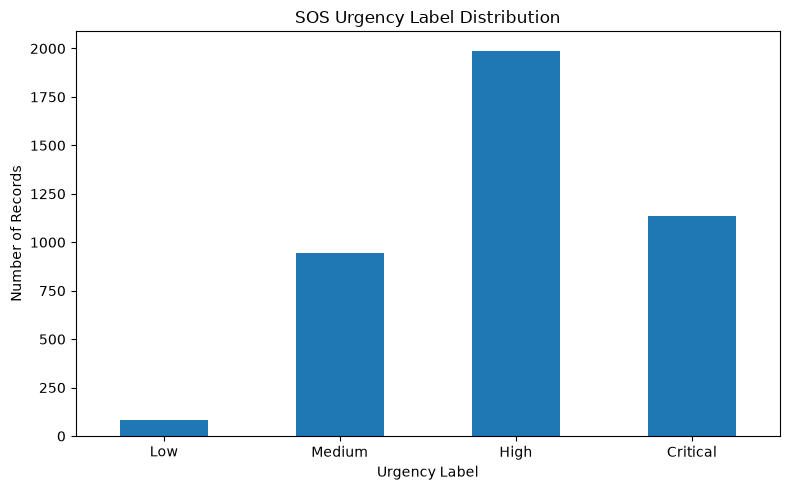

In [6]:

# Cell 5: Analyze and visualize urgency labels

import matplotlib.pyplot as plt

# Count records for each urgency class in the correct order
label_counts = df["urgency_label"].value_counts().reindex(
    ["Low", "Medium", "High", "Critical"],
    fill_value=0
)

# Calculate the percentage of each class
label_percentages = (label_counts / len(df) * 100).round(2)

# Display the results in a table
label_summary = pd.DataFrame({
    "Record Count": label_counts,
    "Percentage (%)": label_percentages
})

display(label_summary)

# Create a bar chart
plt.figure(figsize=(8, 5))
label_counts.plot(kind="bar")

plt.title("SOS Urgency Label Distribution")
plt.xlabel("Urgency Label")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Number of numeric features: 18
Numeric features: ['people_affected', 'people_trapped', 'injuries_reported', 'medical_emergency', 'rescue_required', 'food_required', 'water_required', 'shelter_required', 'water_level_Rapidly_Rising', 'water_level_Rising', 'water_level_Stable', 'building_condition_Collapsing', 'building_condition_Damaged', 'building_condition_Intact', 'building_condition_Unknown', 'location_risk_High', 'location_risk_Low', 'location_risk_Medium']


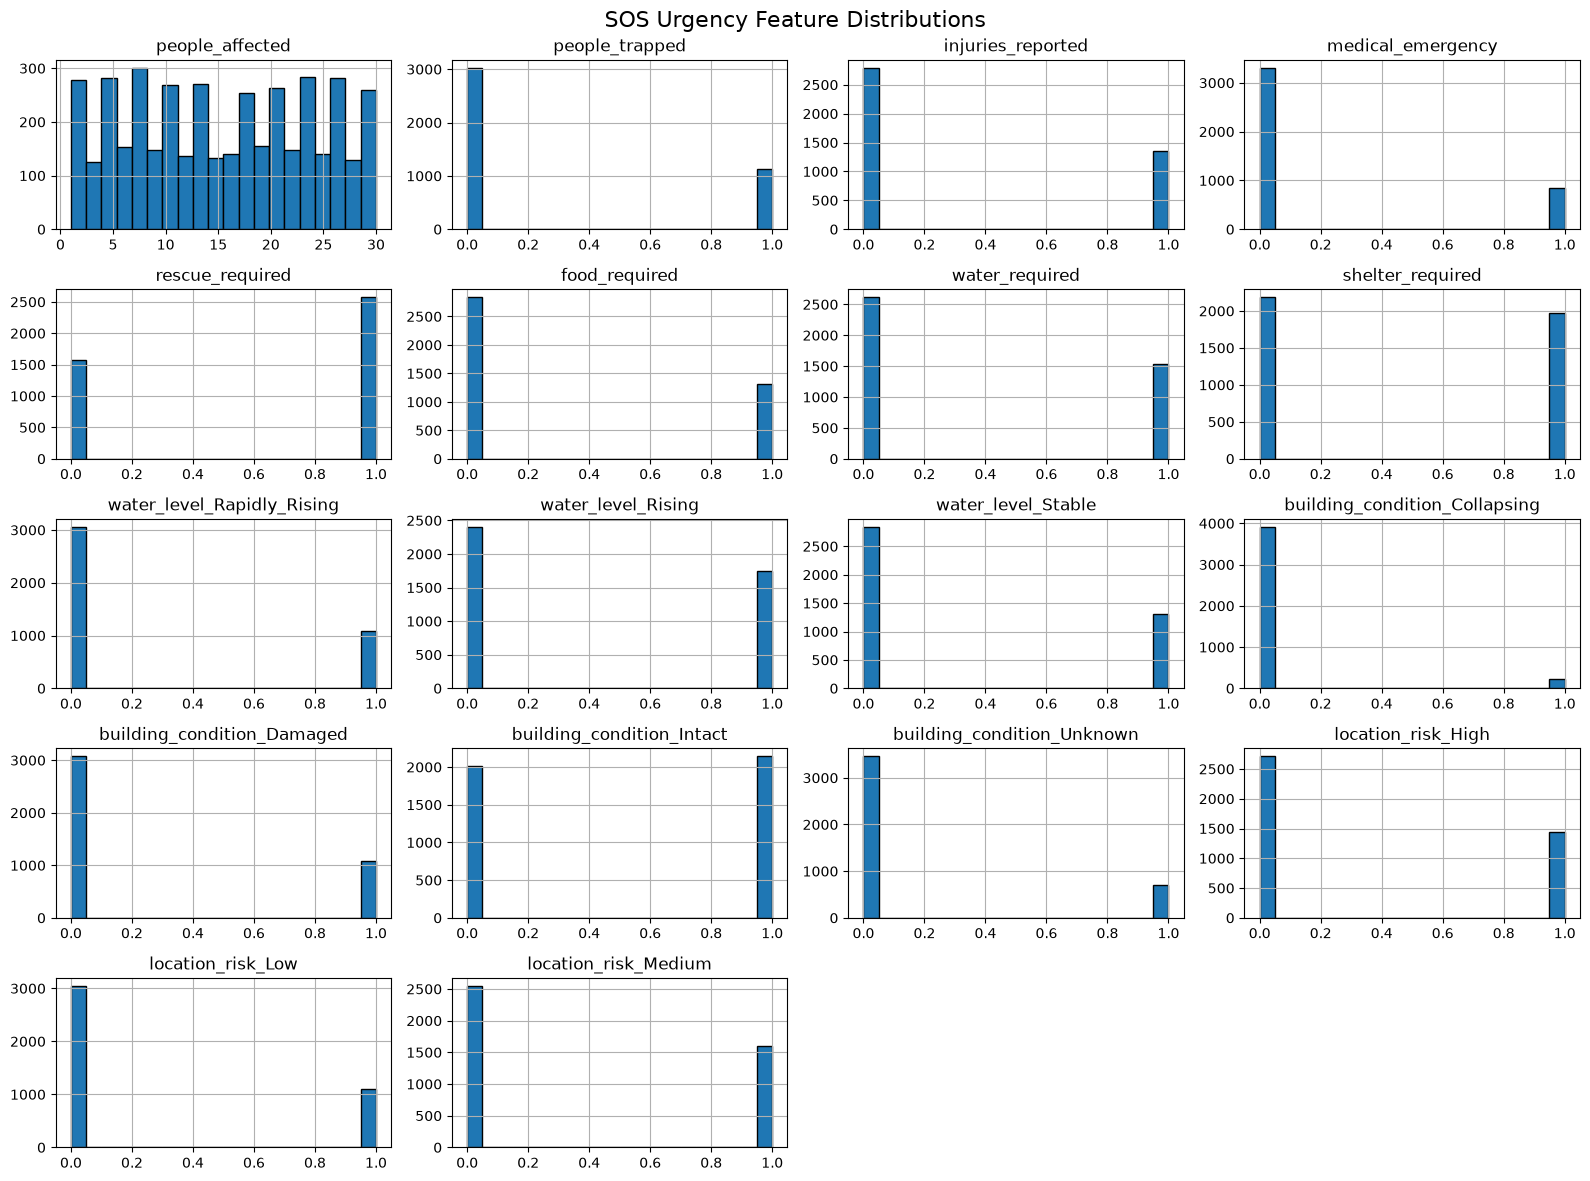

In [7]:

# Cell 6: Explore the distribution of SOS input features

import matplotlib.pyplot as plt

# Select numeric input features, excluding the urgency target
numeric_features = df.select_dtypes(include="number").columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Numeric features:", numeric_features)

# Plot histograms for numeric features
df[numeric_features].hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black" 
)

plt.suptitle("SOS Urgency Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()


Mean feature values for each urgency class:


urgency_label,Low,Medium,High,Critical
people_affected,14.964706,15.485714,15.532931,15.114537
people_trapped,0.000000,0.000000,0.308698,0.451982
injuries_reported,0.000000,0.000000,0.501760,0.318943
medical_emergency,0.000000,0.000000,0.000503,0.744493
rescue_required,0.000000,0.000000,0.722976,1.000000
food_required,0.011765,0.332275,0.342886,0.281938
water_required,0.011765,0.438095,0.356963,0.364758
shelter_required,0.011765,0.526984,0.461036,0.487225
water_level_Rapidly_Rising,0.294118,0.263492,0.179990,0.407048
water_level_Rising,0.329412,0.417989,0.468074,0.348018


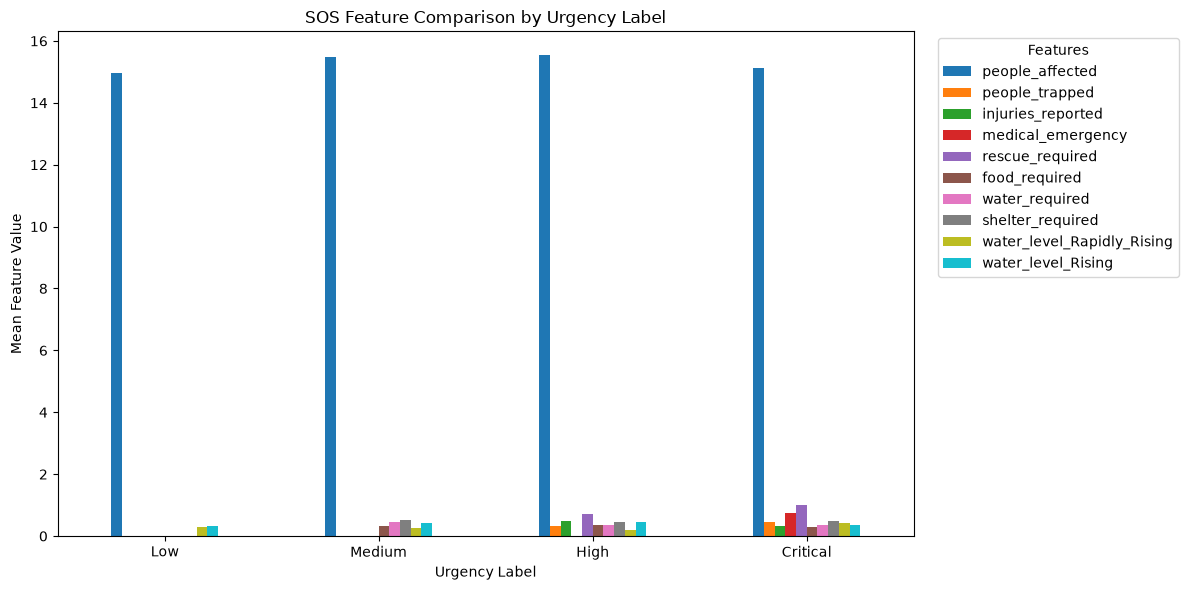

In [8]:

# Cell 7: Compare input features across urgency classes

import matplotlib.pyplot as plt

# Select numeric features, excluding the target label
numeric_features = df.select_dtypes(include="number").columns.tolist()

# Calculate the mean value of each numeric feature for each urgency class
feature_means = df.groupby("urgency_label")[numeric_features].mean()

# Display classes in a consistent order
urgency_order = ["Low", "Medium", "High", "Critical"]
feature_means = feature_means.reindex(urgency_order)

print("Mean feature values for each urgency class:")
display(feature_means.T)

# Plot the first 10 numeric features for easier comparison
features_to_plot = numeric_features[:10]

feature_means[features_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("SOS Feature Comparison by Urgency Label")
plt.xlabel("Urgency Label")
plt.ylabel("Mean Feature Value")
plt.xticks(rotation=0)
plt.legend(title="Features", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


Feature Correlation Matrix:


,people_affected,people_trapped,injuries_reported,medical_emergency,rescue_required,food_required,water_required,shelter_required,water_level_Rapidly_Rising,water_level_Rising,water_level_Stable,building_condition_Collapsing,building_condition_Damaged,building_condition_Intact,building_condition_Unknown,location_risk_High,location_risk_Low,location_risk_Medium
people_affected,1.00,-0.01,0.02,-0.00,-0.00,0.02,-0.01,-0.02,-0.00,0.03,-0.03,-0.03,-0.00,-0.00,0.02,-0.01,-0.02,0.02
people_trapped,-0.01,1.00,-0.05,-0.01,0.48,-0.01,-0.03,-0.01,0.02,0.00,-0.02,-0.00,0.00,0.02,-0.02,0.03,-0.03,0.01
injuries_reported,0.02,-0.05,1.00,-0.00,0.55,-0.00,-0.03,-0.03,-0.02,0.03,-0.01,-0.02,0.00,0.03,-0.03,0.00,-0.02,0.01
medical_emergency,-0.00,-0.01,-0.00,1.00,0.40,-0.02,-0.01,-0.01,-0.02,0.02,-0.00,-0.00,0.03,-0.01,-0.02,-0.01,-0.00,0.01
rescue_required,-0.00,0.48,0.55,0.40,1.00,-0.01,-0.04,-0.03,-0.02,0.02,-0.01,-0.02,0.01,0.03,-0.05,-0.00,-0.02,0.02
food_required,0.02,-0.01,-0.00,-0.02,-0.01,1.00,-0.01,-0.05,-0.06,0.06,-0.01,-0.05,-0.01,0.05,-0.02,0.01,-0.01,-0.00
water_required,-0.01,-0.03,-0.03,-0.01,-0.04,-0.01,1.00,-0.00,-0.01,0.01,0.00,0.01,-0.01,0.00,-0.00,-0.00,-0.01,0.01
shelter_required,-0.02,-0.01,-0.03,-0.01,-0.03,-0.05,-0.00,1.00,-0.01,-0.01,0.02,0.26,0.62,-0.50,-0.22,-0.01,-0.01,0.02
water_level_Rapidly_Rising,-0.00,0.02,-0.02,-0.02,-0.02,-0.06,-0.01,-0.01,1.00,-0.51,-0.41,0.01,-0.01,0.00,0.01,0.02,-0.00,-0.01
water_level_Rising,0.03,0.00,0.03,0.02,0.02,0.06,0.01,-0.01,-0.51,1.00,-0.58,-0.02,0.00,0.01,-0.01,0.00,-0.00,0.00


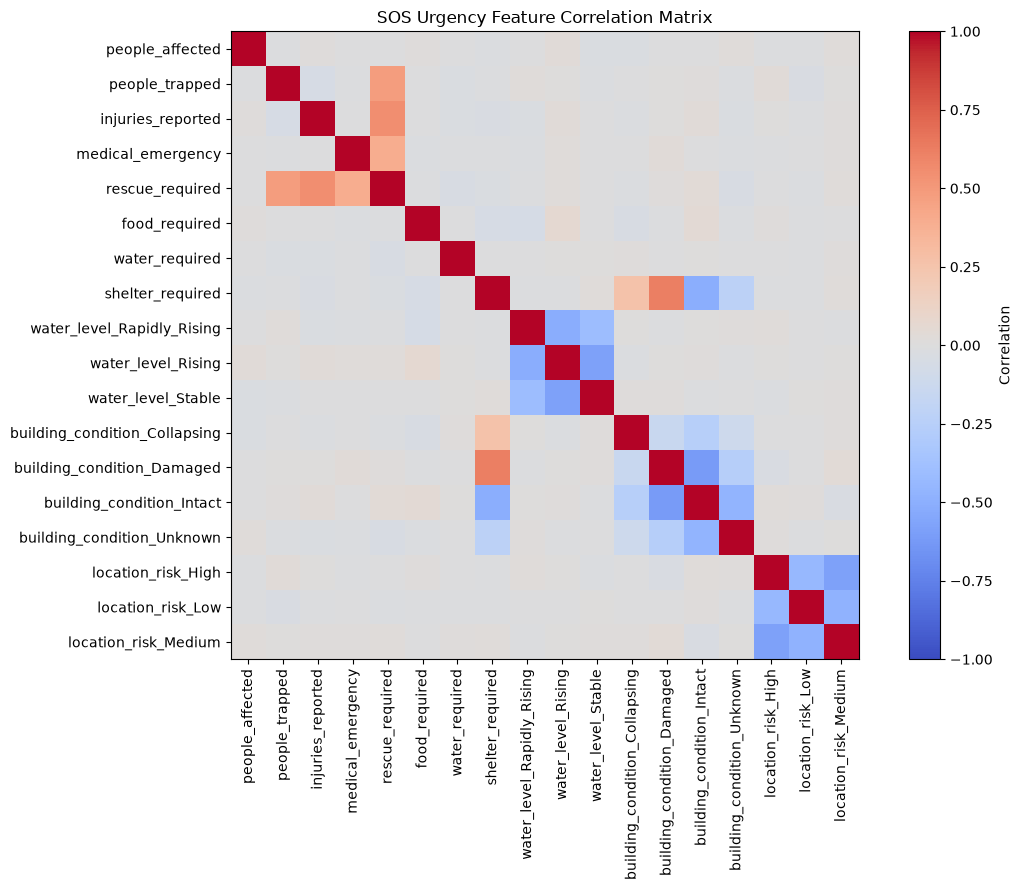

In [9]:

# Cell 8: Analyze correlations between numeric SOS features

import matplotlib.pyplot as plt

# Select numeric input features, excluding the target label
numeric_features = df.select_dtypes(include="number").columns.tolist()

# Calculate correlations between features
correlation_matrix = df[numeric_features].corr()

# Display the correlation values
print("Feature Correlation Matrix:")
display(correlation_matrix.round(2))

# Visualize the correlation matrix
plt.figure(figsize=(12, 9))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(image, label="Correlation")

plt.xticks(
    range(len(numeric_features)),
    numeric_features,
    rotation=90
)
plt.yticks(
    range(len(numeric_features)),
    numeric_features
)

plt.title("SOS Urgency Feature Correlation Matrix")
plt.tight_layout()
plt.show()


In [10]:

# Cell 9: Identify constant features

# Exclude the target label from the feature check
feature_columns = [
    column for column in df.columns
    if column != "urgency_label"
]

# Find columns that contain only one unique value
constant_features = [
    column for column in feature_columns
    if df[column].nunique(dropna=False) <= 1
]

# Display the results
if constant_features:
    print("Constant features found:")
    for column in constant_features:
        print(column)
else:
    print("No constant features found.")

print("\nNumber of constant features:", len(constant_features))


No constant features found.

Number of constant features: 0


In [11]:

# Cell 10: Generate the SOS Urgency EDA Summary Report

import json
from pathlib import Path

# Summarize urgency label counts
label_counts = df["urgency_label"].value_counts().to_dict()

# Summarize missing values
missing_values = df.isnull().sum()
missing_summary = {
    column: int(count)
    for column, count in missing_values.items()
    if count > 0
}

# Prepare the EDA report
eda_report = {
    "dataset_name": "SOS Urgency Dataset",
    "number_of_records": int(df.shape[0]),
    "number_of_columns": int(df.shape[1]),
    "target_column": "urgency_label",
    "urgency_label_counts": {
        str(label): int(count)
        for label, count in label_counts.items()
    },
    "total_missing_values": int(df.isnull().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "constant_features": constant_features,
    "data_limitation": (
        "Records and urgency labels are synthetic/rule-generated. "
        "Results describe this prototype dataset and do not establish "
        "real-world emergency prediction accuracy."
    )
}

# Display the report
print("SOS URGENCY EDA SUMMARY")
print(json.dumps(eda_report, indent=4))

# Save the report beside the dataset
report_path = (
    Path(r"C:\Users\ishit\jeevan_link_ml\Data\Processed_data")
    / "sos_urgency_dataset"
    / "sos_urgency_eda_report.json"
)

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(eda_report, file, indent=4)

print("\nEDA report saved to:")
print(report_path)


SOS URGENCY EDA SUMMARY
{
    "dataset_name": "SOS Urgency Dataset",
    "number_of_records": 4154,
    "number_of_columns": 19,
    "target_column": "urgency_label",
    "urgency_label_counts": {
        "High": 1989,
        "Critical": 1135,
        "Medium": 945,
        "Low": 85
    },
    "total_missing_values": 0,
    "duplicate_rows": 0,
    "constant_features": [],
    "data_limitation": "Records and urgency labels are synthetic/rule-generated. Results describe this prototype dataset and do not establish real-world emergency prediction accuracy."
}

EDA report saved to:
C:\Users\ishit\jeevan_link_ml\Data\Processed_data\sos_urgency_dataset\sos_urgency_eda_report.json
